# Import Libraries

In [61]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import grangercausalitytests

# Download Financial Data

Download 5 years of USD Index. Columns Volume, Dividends and Stock Splits are not required, since they are constant and equal to 0.0

In [62]:
ticker_symbol = 'DX-Y.NYB'

ticker = yf.Ticker(ticker_symbol)
df = ticker.history(period='5y').drop(columns=['Volume', 'Dividends', 'Stock Splits']).reset_index(drop=False)
df

,Date,Open,High,Low,Close
0,2021-10-27 00:00:00-04:00,93.970001,94.010002,93.690002,93.860001
1,2021-10-28 00:00:00-04:00,93.879997,93.970001,93.279999,93.349998
2,2021-10-29 00:00:00-04:00,93.360001,94.300003,93.320000,94.120003
3,2021-11-01 00:00:00-04:00,94.129997,94.309998,93.860001,93.879997
4,2021-11-02 00:00:00-04:00,93.930000,94.129997,93.820000,94.089996
...,...,...,...,...,...
1252,2026-10-21 00:00:00-04:00,101.779999,101.839996,101.639999,101.779999
1253,2026-10-22 00:00:00-04:00,101.709999,101.879997,101.449997,101.610001
1254,2026-10-23 00:00:00-04:00,101.570000,101.849998,101.489998,101.809998
1255,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999


# Construct Line Plot of HLC Data

In [63]:
fig = px.line(df, x='Date', y=['High', 'Close', 'Low'], title='USD Price Index from 2021 to 2026')
fig.show()

In [64]:
stats = df[['Open', 'High', 'Low', 'Close']].agg(['mean', 'std'])
display(stats)

,Open,High,Low,Close
mean,102.247764,102.580570,101.925534,102.260360
std,3.819153,3.872418,3.753589,3.816276


TASK 1

OHLCV Variables

Open: The price at which the currency starts trading at the beginning of the day.

High: The highest price reached during that trading day.

Low: The lowest price reached during that trading day.

Close: The final price when the market closes for the day (usually the most important reference price).

Volume: The total number of units or contracts traded during the day

Mean: The average USD Index price is around 102.2 across all metrics. Open (102.23) and Close (102.25) are almost identical, while High (102.57) and Lo2 (101.91) naturally bound the upper and lower averages.
Standard Deviation (std): All four variables show a very similar


standard deviation of about 3.8 Open: 3.83, Close: 3.83, High: 3.89, Low: 3.77. This shows that the daily series move closely together and have the same overall dispersion/volatility over time.

TASK 2

Looking at the line plot, the High, Low, and Close series are clearly non-stationary. A stationary series needs to have a constant mean and variance over time, moving around a flat horizontal line. Here, the USD price has strong upward and downward trends across different years, and the volatility changes a lot depending on the period.

TASK 3

In [65]:
from statsmodels.tsa.stattools import adfuller, kpss

# Λίστα με τις μεταβλητές που θέλουμε να ελέγξουμε
cols = ['Open', 'High', 'Low', 'Close']

for col in cols:
    series = df[col].dropna()

    # 1. ADF Test
    adf_res = adfuller(series)
    print(f"--- {col} ---")
    print(f"ADF p-value: {adf_res[1]:.4f}")

    # 2. KPSS Test
    kpss_res = kpss(series, regression='c', nlags='auto')
    print(f"KPSS p-value: {kpss_res[1]:.4f}\n")

--- Open ---
ADF p-value: 0.0692
KPSS p-value: 0.0100

--- High ---
ADF p-value: 0.0757
KPSS p-value: 0.0100

--- Low ---
ADF p-value: 0.0757
KPSS p-value: 0.0100

--- Close ---
ADF p-value: 0.1089
KPSS p-value: 0.0100



/tmp/ipykernel_1593/250978330.py:10: FutureWarning:

adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.

/tmp/ipykernel_1593/250978330.py:15: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.

/tmp/ipykernel_1593/250978330.py:15: FutureWarning:

kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current 

ADF Test (p-values greater than 0.05): Because the p-values are around 0.08 - 0.10 (greater than 0.05), we do not reject the null hypothesis, which means that the series has a unit root (it is non-stationary).

KPSS Test (p-values = 0.01): Because the p-value is 0.01 (less than 0.05), we reject the null hypothesis stating that the series is stationary, confirming once again that it is non-stationary.

TASK 4

In [66]:
train_size = 0.7
history_size = 30

num_train_samples = int(df.shape[0]*train_size)
train_df = df.iloc[:num_train_samples]
test_df = df.iloc[num_train_samples - history_size:]

train_df.shape, test_df.shape

((879, 5), (408, 5))

TASK 5

In [67]:
def construct_timeframes(df, H):
    inputs = df.drop(columns=['Date']).to_numpy(dtype=np.float64)
    x = np.array([inputs[i-H: i].flatten() for i in range(H, df.shape[0])])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

H=1  Train MAE: 0.3709, Test MAE: 0.3003
H=5  Train MAE: 0.3670, Test MAE: 0.3036
H=15  Train MAE: 0.3609, Test MAE: 0.3048
H=30  Train MAE: 0.3530, Test MAE: 0.3204


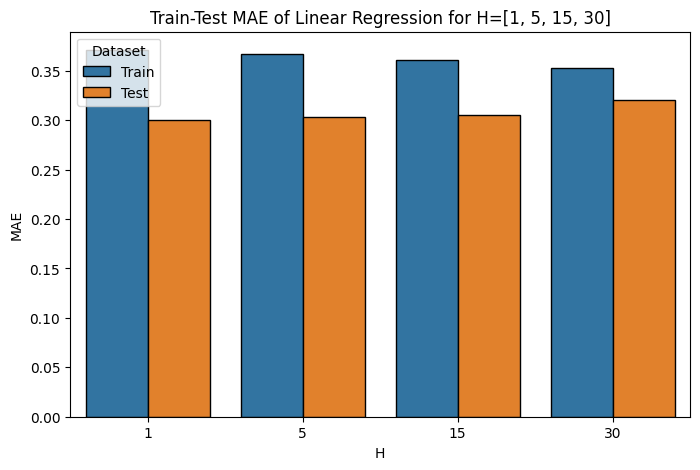

In [68]:
H_values = [1, 5, 15, 30]
results = []

for H in H_values:
    x_train, y_train = construct_timeframes(train_df, H=H)
    x_test, y_test = construct_timeframes(test_df, H=H)

    model = LinearRegression()
    model.fit(x_train, y_train)

    y_pred_train = model.predict(x_train)
    train_mae = mean_absolute_error(y_true=y_train, y_pred=y_pred_train)

    y_pred_test = model.predict(x_test)
    test_mae = mean_absolute_error(y_true=y_test, y_pred=y_pred_test)

    results.append({'H': H, 'Dataset': 'Train', 'MAE': train_mae})
    results.append({'H': H, 'Dataset': 'Test', 'MAE': test_mae})

    print(f"H={H}  Train MAE: {train_mae:.4f}, Test MAE: {test_mae:.4f}")

# Barplot
metrics_df = pd.DataFrame(results)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=metrics_df, x='H', y='MAE', hue='Dataset', edgecolor='black')
ax.set_title('Train-Test MAE of Linear Regression for H=[1, 5, 15, 30]')
plt.show()

TASK 6

In [69]:
history_size = 30

# Υπολογισμός προβλέψεων και για τα δύο σύνολα
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

train_dates = train_df['Date'].iloc[history_size:]
test_dates = test_df['Date'].iloc[history_size:]


fig = go.Figure()


fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_train)[-history_size:],
    mode='lines',
    name='Train (Actual)',
    line=dict(color='royalblue', width=2)
))

#  Training predicted data
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_pred_train)[-history_size:],
    mode='lines',
    name='Train (Predicted)',
    line=dict(color='orange', width=2)
))

#  Test actual values
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_test),
    mode='lines',
    name='Test (Actual)',
    line=dict(color='royalblue', width=2, dash='dash')
))

# Vertical dashed line separating train/test
fig.add_shape(
    type='line',
    x0=test_dates.iloc[0],
    x1=test_dates.iloc[0],
    y0=0,
    y1=1,
    xref='x',
    yref='paper',
    line=dict(color='black', width=2, dash='dash')
)

#  Prediction line for test set
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_pred_test),
    mode='lines',
    name='Test (Predicted)',
    line=dict(color='#E63946', width=2.5)
))

# Layout
fig.update_layout(
    title='USD Price Index — Close Price Prediction (H=30)',
    xaxis_title='Date',
    yaxis_title='Price ($)',
    template='plotly_white',
    width=1200,
    height=600,
    legend=dict(x=0.01, y=0.99),
    hovermode='x unified'
)

fig.show()

The predictions follow the actual prices closely in both the train and test sets, with a low error (Train MAE = 0.3530, Test MAE = 0.3203 the test error is slightly lower because the test period is less volatile). However, looking closely at the sharp peaks and drops the predicted line is slightly shifted to the right (a 1-step lag) and slightly smooths out extreme spikes. Because the series is non-stationary, the model mainly relies on yesterday's price (t-1) to guess today's price (t), while the other 29 days in the window don't add much useful information and just cause slight overfitting on the training set

TASK 7

Log-Returns H=1  Train MAE: 0.3707, Test MAE: 0.2906
Log-Returns H=5  Train MAE: 0.3685, Test MAE: 0.2887
Log-Returns H=15  Train MAE: 0.3625, Test MAE: 0.2881
Log-Returns H=30  Train MAE: 0.3536, Test MAE: 0.3053


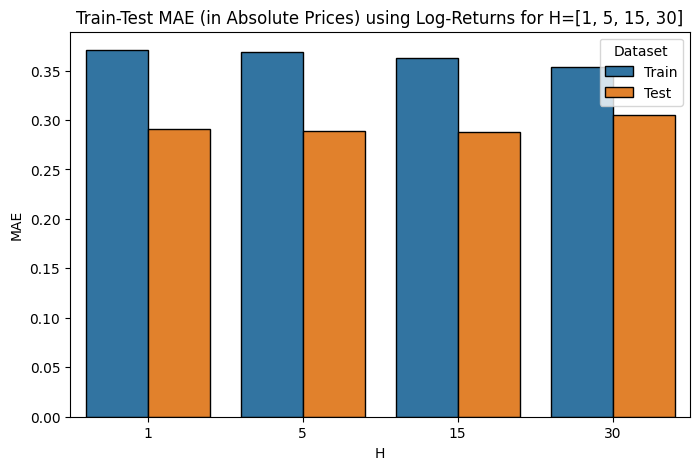

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

#  Υπολογισμός Log-Returns
vars_cols = ['Open', 'High', 'Low', 'Close']
df_logr = df.copy()
df_logr[vars_cols] = np.log(df_logr[vars_cols] / df_logr[vars_cols].shift(1))
df_logr = df_logr.dropna().reset_index(drop=True)


df_aligned = df.iloc[1:].reset_index(drop=True)


def log_returns_to_absolute_prices(prices, log_returns):
    return prices * np.exp(log_returns)


split_idx = int(len(df_logr) * 0.7)

train_logr = df_logr.iloc[:split_idx].copy()
test_logr = df_logr.iloc[split_idx:].copy()

train_abs = df_aligned.iloc[:split_idx].copy()
test_abs = df_aligned.iloc[split_idx:].copy()

# Επανάληψη του Ερωτήματος 5 για H = [1, 5, 15, 30]
H_values = [1, 5, 15, 30]
results_logr = []

for H in H_values:
    # Παράθυρα πάνω στα Log-Returns
    x_train, y_train_logr = construct_timeframes(train_logr, H=H)
    x_test, y_test_logr = construct_timeframes(test_logr, H=H)

    # Εκπαίδευση μοντέλου να προβλέπει το Log-Return της επόμενης ημέρας
    model = LinearRegression()
    model.fit(x_train, y_train_logr)

    pred_train_logr = model.predict(x_train)
    pred_test_logr = model.predict(x_test)


    train_prev_prices = train_abs['Close'].to_numpy(dtype=np.float64)[H-1:-1]
    train_true_prices = train_abs['Close'].to_numpy(dtype=np.float64)[H:]

    test_prev_prices = test_abs['Close'].to_numpy(dtype=np.float64)[H-1:-1]
    test_true_prices = test_abs['Close'].to_numpy(dtype=np.float64)[H:]

    pred_train_prices = log_returns_to_absolute_prices(train_prev_prices, pred_train_logr)
    pred_test_prices = log_returns_to_absolute_prices(test_prev_prices, pred_test_logr)

    train_mae = mean_absolute_error(train_true_prices, pred_train_prices)
    test_mae = mean_absolute_error(test_true_prices, pred_test_prices)

    results_logr.append({'H': H, 'Dataset': 'Train', 'MAE': train_mae})
    results_logr.append({'H': H, 'Dataset': 'Test', 'MAE': test_mae})

    print(f"Log-Returns H={H}  Train MAE: {train_mae:.4f}, Test MAE: {test_mae:.4f}")

#  Ραβδόγραμμα αποτελεσμάτων
metrics_logr_df = pd.DataFrame(results_logr)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=metrics_logr_df, x='H', y='MAE', hue='Dataset', edgecolor='black')
ax.set_title('Train-Test MAE (in Absolute Prices) using Log-Returns for H=[1, 5, 15, 30]')
plt.show()

Using Log-Returns gives a lower Test MAE across all window sizes compared to the raw prices in Question 5 (for example, 0.2909 vs 0.3007 at H=1, and 0.3059 vs 0.3224 at H=30).Less overfitting Unlike the raw-price model which got worse right away as H increased, the Log-Returns model actually improves up to H=15, reaching the lowest overall error (Test MAE: 0.2890 vs 0.3111 in Q5). Since log-returns are stationary, the model handles larger windows much better and only starts overfitting slightly at H=30.

TASK 8

In [71]:
from statsmodels.tsa.stattools import grangercausalitytests

history_size = 30
data = train_df[['Close', 'Open']]

# Computing log-returns
data = np.log(data / data.shift(1)).dropna()


results = grangercausalitytests(data[['Close', 'Open']], maxlag=history_size)


p_values = {
    lag: results[lag][0]['ssr_ftest'][1]
    for lag in range(1, history_size + 1)
}
results_df = pd.DataFrame({'Lag (H)': list(p_values.keys()), 'P-value': list(p_values.values())})
results_df['Significant'] = results_df['P-value'] < 0.05

display(results_df)
print("Significant lags (p < 0.05):", results_df[results_df['Significant']]['Lag (H)'].tolist())

,Lag (H),P-value,Significant
0,1,0.007623,True
1,2,0.858932,False
2,3,0.402175,False
3,4,0.914104,False
4,5,0.634647,False
5,6,0.879679,False
6,7,0.926891,False
7,8,0.710748,False
8,9,0.795743,False
9,10,0.806453,False


Significant lags (p < 0.05): [1, 30]


Yes, Open is useful for predicting Close since the Granger Causality test gives p-values less than 0.05. The only statistically significant steps are lag 1 and lag 30, meaning yesterday's Open (lag 1) holds the main predictive value while lags 2 to 29 are not significant.

TASK 9

/tmp/ipykernel_1593/3366375522.py:14: FutureWarning:

YF.download() has changed argument auto_adjust default to True



Extended Features H=1 - Train MAE: 0.3654, Test MAE: 0.2894
Extended Features H=5 - Train MAE: 0.3612, Test MAE: 0.2917
Extended Features H=15 - Train MAE: 0.3459, Test MAE: 0.3078
Extended Features H=30 - Train MAE: 0.3195, Test MAE: 0.3559


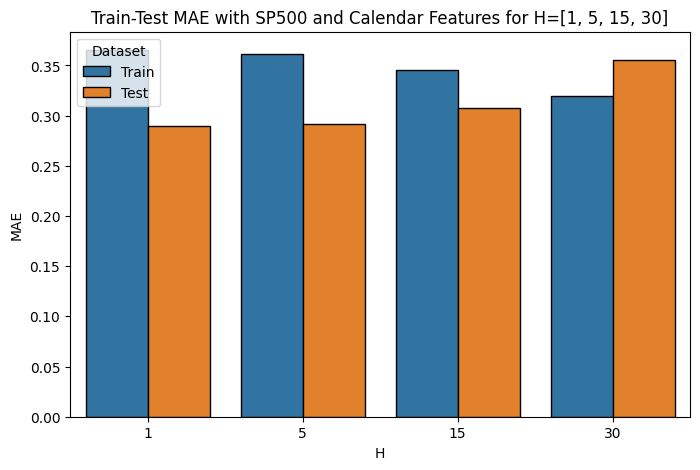

In [72]:
import yfinance as yf
import holidays
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

#  Λήψη του SP 500  και ένωση με το df
start_date = df['Date'].min().strftime('%Y-%m-%d')
end_date = (df['Date'].max() + pd.Timedelta(days=1)).strftime('%Y-%m-%d')

sp500 = yf.download('^GSPC', start=start_date, end=end_date, progress=False).reset_index()
if isinstance(sp500.columns, pd.MultiIndex):
    sp500.columns = sp500.columns.get_level_values(0)

sp500 = sp500[['Date', 'Close']].rename(columns={'Close': 'SP500'})
sp500['Date'] = pd.to_datetime(sp500['Date']).dt.tz_localize(None)

df_ext = df.copy()
df_ext['Date'] = pd.to_datetime(df_ext['Date']).dt.tz_localize(None)
df_ext = pd.merge(df_ext, sp500, on='Date', how='left')
df_ext['SP500'] = df_ext['SP500'].ffill().bfill()

#  Ημερολογιακά χαρακτηριστικά and Holidays
df_ext['Month'] = df_ext['Date'].dt.month
df_ext['DayOfWeek'] = df_ext['Date'].dt.dayofweek

us_holidays = holidays.country_holidays('US')
nyse_holidays = holidays.financial_holidays('NYSE')

global_events = {
    'NewYearsDay': (1, 1), 'ValentinesDay': (2, 14), 'WomensDay': (3, 8),
    'AprilFools': (4, 1), 'EarthDay': (4, 22), 'LabourDay': (5, 1),
    'EnvironmentDay': (6, 5), 'Halloween': (10, 31), 'ChristmasEve': (12, 24),
    'ChristmasDay': (12, 25), 'BoxingDay': (12, 26), 'NewYearsEve': (12, 31),
}
event_dates = set(global_events.values())

df_ext['IsHoliday'] = df_ext['Date'].dt.date.map(
    lambda d: int(d in us_holidays or d in nyse_holidays or (d.month, d.day) in event_dates)
)

#  Μετατροπή  σε Log-Returns
price_cols = ['Open', 'High', 'Low', 'Close', 'SP500']
future_cols = ['Month', 'DayOfWeek', 'IsHoliday']

df_logr_ext = df_ext.copy()
df_logr_ext[price_cols] = np.log(df_logr_ext[price_cols] / df_logr_ext[price_cols].shift(1))
df_logr_ext = df_logr_ext.dropna().reset_index(drop=True)

df_abs_ext = df_ext.iloc[1:].reset_index(drop=True)

#  timeframes που προσθέτει και τα γνωστά μελλοντικά features της ημέρας i (t+1)
def construct_timeframes_with_future(df, H, future_cols=['Month', 'DayOfWeek', 'IsHoliday']):
    all_inputs = df.drop(columns=['Date'], errors='ignore').to_numpy(dtype=np.float64)
    future_inputs = df[future_cols].to_numpy(dtype=np.float64)

    x = np.array([
        np.concatenate([all_inputs[i-H: i].flatten(), future_inputs[i]])
        for i in range(H, df.shape[0])
    ])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

#   Αξιολόγηση για H = [1, 5, 15, 30]
split_idx = int(len(df_logr_ext) * 0.7)
train_logr = df_logr_ext.iloc[:split_idx].copy()
test_logr = df_logr_ext.iloc[split_idx:].copy()

train_abs = df_abs_ext.iloc[:split_idx].copy()
test_abs = df_abs_ext.iloc[split_idx:].copy()

H_values = [1, 5, 15, 30]
results_ext = []

for H in H_values:
    x_train, y_train_logr = construct_timeframes_with_future(train_logr, H=H)
    x_test, y_test_logr = construct_timeframes_with_future(test_logr, H=H)

    model = LinearRegression()
    model.fit(x_train, y_train_logr)

    pred_train_logr = model.predict(x_train)
    pred_test_logr = model.predict(x_test)


    train_prev = train_abs['Close'].to_numpy(dtype=np.float64)[H-1:-1]
    train_true = train_abs['Close'].to_numpy(dtype=np.float64)[H:]
    test_prev = test_abs['Close'].to_numpy(dtype=np.float64)[H-1:-1]
    test_true = test_abs['Close'].to_numpy(dtype=np.float64)[H:]

    pred_train_prices = log_returns_to_absolute_prices(train_prev, pred_train_logr)
    pred_test_prices = log_returns_to_absolute_prices(test_prev, pred_test_logr)

    train_mae = mean_absolute_error(train_true, pred_train_prices)
    test_mae = mean_absolute_error(test_true, pred_test_prices)

    results_ext.append({'H': H, 'Dataset': 'Train', 'MAE': train_mae})
    results_ext.append({'H': H, 'Dataset': 'Test', 'MAE': test_mae})

    print(f"Extended Features H={H} - Train MAE: {train_mae:.4f}, Test MAE: {test_mae:.4f}")

#  Ραβδόγραμμα
metrics_ext_df = pd.DataFrame(results_ext)
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=metrics_ext_df, x='H', y='MAE', hue='Dataset', edgecolor='black')
ax.set_title('Train-Test MAE with SP500 and Calendar Features for H=[1, 5, 15, 30]')
plt.show()

Adding the S&P 500 and calendar features gives a slightly better Test MAE at H=1 (0.2898). However, as H increases to 15 and 30, the Test MAE gets much worse (0.3557 at H=30) while Train MAE drops to 0.3195, because having so many extra features causes the model to overfit.